# **Intro to Generative AI for Engineers**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# 📖 TABLE OF CONTENTS

- [Setup](#Setup)
- [What is Artificial Intelligence?](#What-is-Artificial-Intelligence?)
  - [Machine Learning](#Machine-Learning)
  - [Generative AI](#Generative-AI)
  - [Agentic AI](#Agentic-AI)
  - [AI vs Deterministic Code](#AI-vs-Deterministic-Code)
- [Key Terminology](#Key-Terminology)
  - [Large Language Model (LLM)](#Large-Language-Model-(LLM))
  - [Tokens](#Tokens)
  - [Hallucination](#Hallucination)
  - [Retrieval-Augmented Generation (RAG)](#Retrieval-Augmented-Generation-(RAG))
  - [Context Window](#Context-Window)
  - [Temperature](#Temperature)
- [References](#References)

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Setup

Before we jump in, let's quickly run the setup cell. It checks the environment (GPU, library versions) and sets random seeds for reproducibility — we want identical results on every run.

In [ ]:
# 🔧 Setup: Run this cell first!
# Environment check + random seeds for reproducibility

import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib as mpl
import torch
import torch.nn as nn

print(f"📦 Python       {sys.version.split()[0]}")
print(f"🔢 NumPy        {np.__version__}")
print(f"🐼 Pandas       {pd.__version__}")
print(f"📊 Matplotlib   {mpl.__version__}")
print(f"🔥 PyTorch      {torch.__version__}")

# GPU check (only needed for optional deep-feature experiments)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"✅ GPU available: {torch.cuda.get_device_name(0)}")
    print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    device = torch.device("cpu")
    print("⚠️ No GPU detected")

DEVICE_LABEL = "GPU" if device.type == "cuda" else "CPU"

# Random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"\n🎲 Random seed set to {SEED} (Python, NumPy, PyTorch)")

%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'   # photos as JPEG, not PNG — ~10× smaller notebook
# Remove character limits for all columns of Pandas dataframes permanently in this session
pd.set_option('display.max_colwidth', None)

📦 Python       3.13.15
🔢 NumPy        2.1.3
🐼 Pandas       2.2.3
📊 Matplotlib   3.10.0
🔥 PyTorch      2.11.0+cpu
⚠️ No GPU detected

🎲 Random seed set to 42 (Python, NumPy, PyTorch)


![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# What is Artificial Intelligence?

Three overlapping ideas live under the AI umbrella. Knowing which one you are dealing with changes how you evaluate, test and trust it.

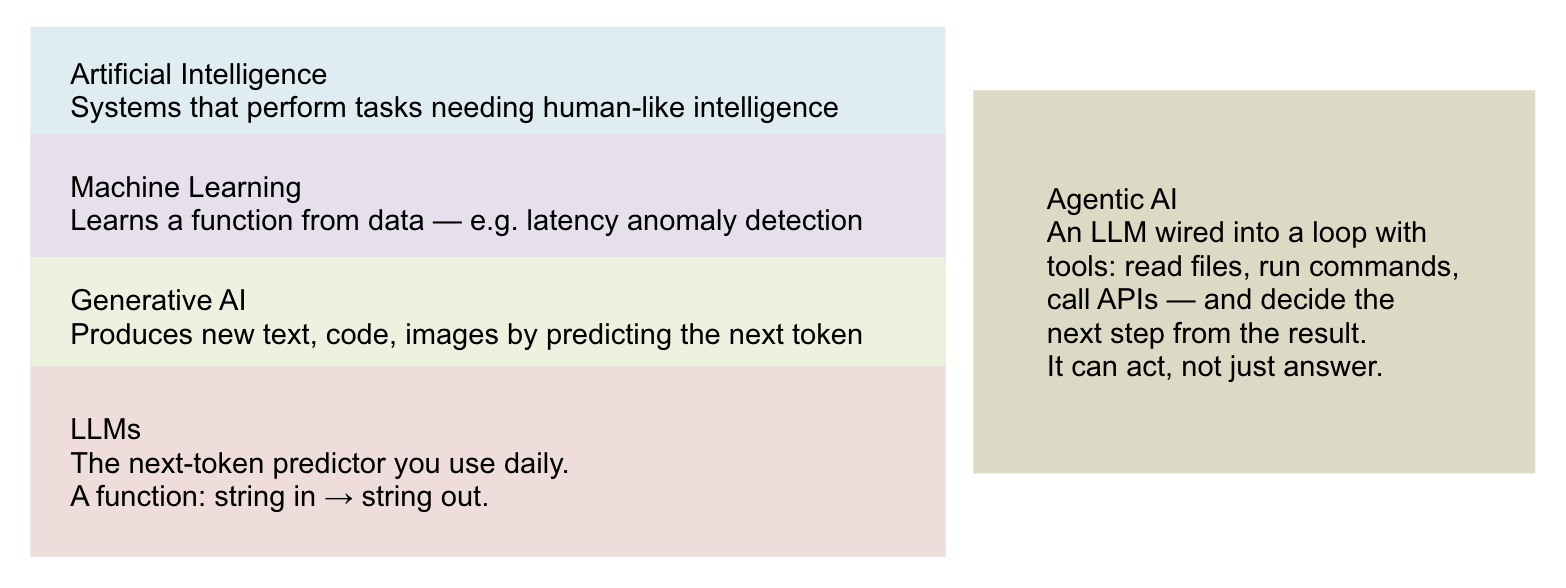

*The AI Landscape*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/AI_Basics_for_Engineers-01.png", width=800))
display(Markdown("*The AI Landscape*"))

## Machine Learning

* Machine learning is the umbrella technique where a system learns a function from data instead of being explicitly programmed.
* You give it labeled examples (supervised), unlabeled examples (unsupervised), or a feedback signal (reinforcement), and the model fits parameters that minimize error on those examples.
* For your team, the most common encounter with classic ML is in observability and platform tooling; anomaly detection on log volume, latency, or error-rate metrics.
* A model learns the normal shape of a service's traffic and flags points that deviate. It does not understand causes; it just notices that something looks unlike the past.

## Generative AI

* Generative AI is the subset of ML that produces new artifacts: text, code, images, audio. Large language models (LLMs) are the variant most engineering teams interact with daily.
* They predict the next token over and over until a stopping condition is met, conditioned on whatever input you give them.
* Generative systems do not look things up. They generate. If the most statistically plausible next tokens describe a function or API that does not exist, you get a fluent confident description of nothing. That failure mode is hallucination, and we will return to it.
    * Strength: compressing patterns across enormous amounts of code, prose, and documentation into a single fluent interface.
    * Weakness: it cannot tell you that it does not know.

## Agentic AI

* An agent is an LLM wired into a loop with tools. It can read files, run commands, call APIs, and decide what to do next based on the results. The same underlying generative model is now allowed to act, not just respond.
* For engineers, agentic systems unlock real automation: an agent can open a branch, edit files, run tests, and open a pull request. The risk profile changes accordingly.
* The question shifts from "is the answer correct?" to "what is this allowed to do, and how do I know when it is done?".

## AI vs Deterministic Code

* Deterministic code, given the same input, returns the same output. You can write a unit test that asserts equality and the test will pass for years. AI systems are probabilistic.
* The same prompt can produce different completions, and the same input can produce subtly different judgments.
* The practical rule: if you can write down the rules, write the code. If you cannot (summarize this log, suggest a refactor, draft a migration), AI earns its place. Mixing the two is fine, but knowing which layer you are in matters.

| Property | Deterministic Code | AI System |
| :------- | :----------------- | :-------- |
| Behaviour on same input | Identical | May vary |
| Failure mode | Throws or returns wrong value | Often returns a confident, plausible wrong value |
| Test strategy | Unit tests, equality assertions | Evals, rubrics, sampling, human review |
| Right home | Anything you can specify precisely | Tasks where "good enough" beats "impossible to specify" |

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# Key Terminology

Shared vocabulary so a code review comment that says "watch the context window" lands the same way across the team.

## Large Language Model (LLM)

* An LLM is a neural network trained on a very large corpus of text and code to predict the next token. "Large" refers to the parameter count (billions to trillions) and the training set size (trillions of tokens).
* Practically, an LLM is a function that takes a string and returns a string, where the output is sampled from a learned probability distribution.
* That is the whole interface. Everything else — chat windows, agents, code assistants — is plumbing around that single primitive.

## Tokens

* LLMs do not see characters or words. They see tokens, which are short sub-word units produced by a tokenizer. A rough heuristic for English: 1 token ≈ 4 characters, or 100 tokens ≈ 75 words. Code tokenizes denser, with curly braces, indentation, and identifiers each becoming their own tokens.
* Why this matters in practice:
    * API pricing is per token, input and output, and a 5000-line log file is a real cost.
    * The context window is measured in tokens, not lines.
    * Truncation happens at token boundaries, which is why pasted JSON can come back with a missing closing brace.

## Hallucination

* A hallucination is a confident, well-formed output that is not grounded in reality. The model is not lying; it is generating the most plausible continuation of your prompt. If your prompt asks for a function from a library that does not have that function, the model is happy to invent one.
* Slopsquatting:
    * Attackers register npm and PyPI packages with names that LLMs commonly hallucinate. An engineer who installs request-promise-utils on the model's suggestion gets a real package — with malware. Always verify package names against the registry before installing, especially for utility-sounding names you have never heard of.
* Mitigations: ask for citations, give the model the real docs in-context (see RAG), and refuse to merge code that uses an unfamiliar dependency without checking the registry yourself.

## Retrieval-Augmented Generation (RAG)

* RAG is the pattern of looking up relevant documents at query time and stuffing them into the prompt before generation. The model still generates, but now its plausible continuations are anchored to text you chose. RAG is the dominant remedy for hallucination on factual tasks.
* A typical engineering RAG flow:
    * Embed your docs (runbooks, ADRs, API specs) into a vector store.
    * At query time, embed the user's question and retrieve the top-k most similar chunks.
    * Prepend those chunks to the prompt with instructions like "answer only from the context above; if it is not there, say so".

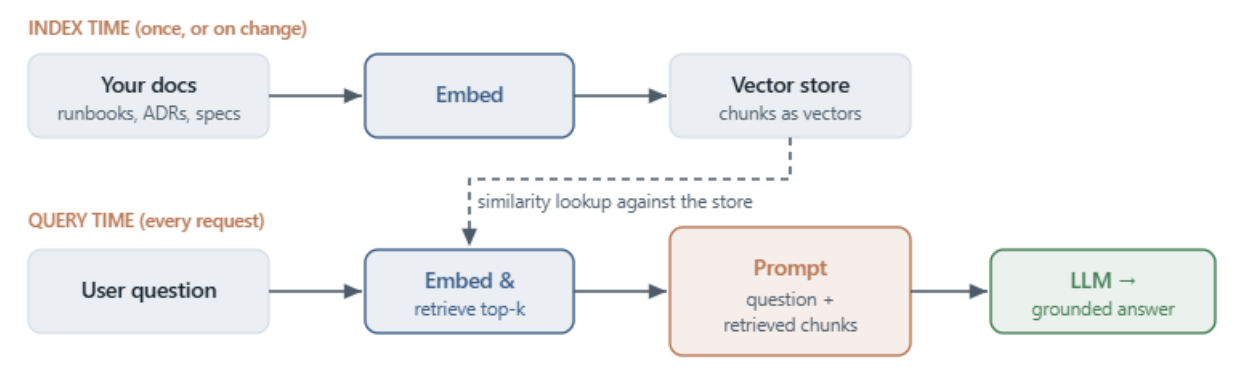

*RAG Reference Flow*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/AI_Basics_for_Engineers-02.png", width=800))
display(Markdown("*RAG Reference Flow*"))

* The model still generates — but its plausible continuations are now anchored to text you chose. Retrieval & chunking quality, not the model, decide the answer quality.
* RAG quality is mostly a chunking, retrieval, and prompting problem, not a model problem. Bad chunks in, bad answers out.

## Context Window

* The context window is the maximum number of tokens the model can attend to in one request, including the system prompt, conversation history, retrieved context, your question, and the generated answer. Older models had 4K or 8K windows; modern ones reach 200K to 1M tokens.
* Large does not mean unlimited or free. Two failure modes:
    * Lost in the middle: evidence buried in the middle of a long context is often ignored relative to evidence near the start or end. Put what matters at the edges.
    * Drift and cost: a long stale conversation costs more per turn and produces lower-quality answers than a fresh, focused one. Restart sessions for new tasks.

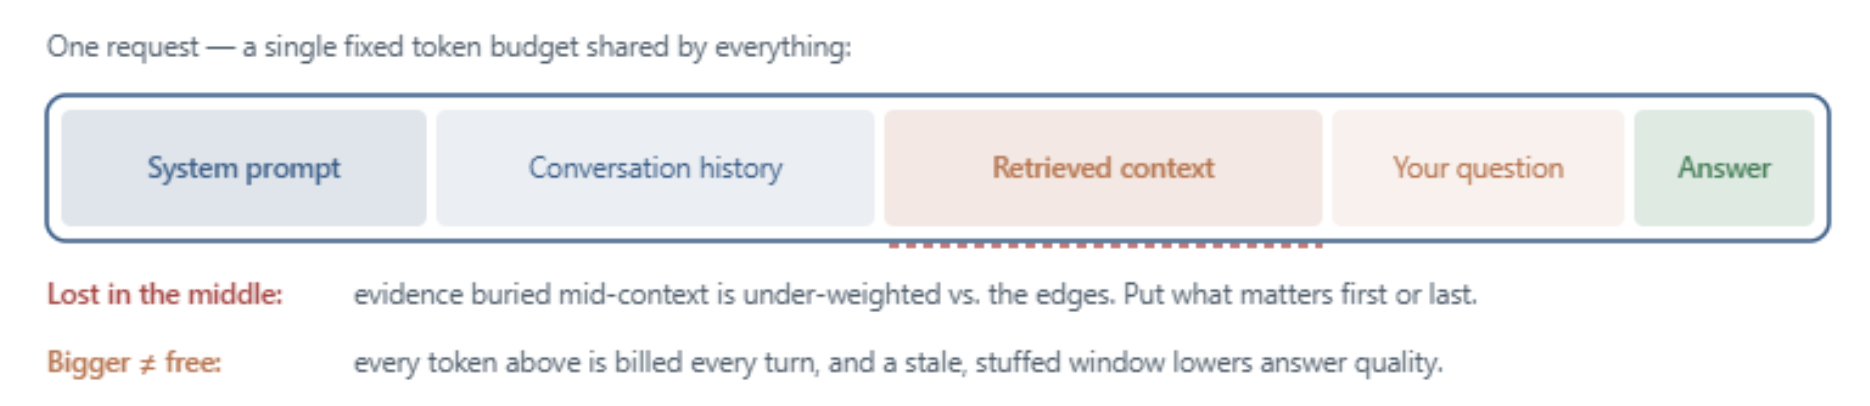

*What fills the Context Window*

In [ ]:
from IPython.display import Image, display, Markdown
display(Image(filename="data/images/AI_Basics_for_Engineers-03.png", width=800))
display(Markdown("*What fills the Context Window*"))

"Context window" is one shared budget, measured in tokens, not lines. Trim to the relevant slice instead of pasting the whole file or the whole history.

## Temperature

* Temperature is a sampling parameter, typically 0 to 1 (some APIs allow upto 2). At temperature 0, the model picks the highest-probability next token every time, which makes output close to deterministic for short prompts. Higher temperatures sample more broadly, producing more varied, creative, and risky completions.
* If you do not control temperature directly (most chat UIs hide it), prompts that say "return only the JSON, no commentary" do similar work.

| Use case | Suggested temperature |
| :------- | :----------------- |
| Code generation, refactors, JSON output | 0 — 0.2 |
| Code explanation, doc drafting | 0.2 — 0.5 |
| Brainstorm, naming, alternative designs | 0.6 — 0.9 |

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# References

- **Photon University: AI Basics for Engineers Course**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)